# Water values and SDDP: a Python walkthrough of ReSDDP

This notebook answers three questions:

1. **What is a water value?** Intuition first (Part 1), then the math (Parts 1-2).
2. **How do water values and a market model fit together, and can they be solved together?** (Part 6)
3. **What does ReSDDP's code do, and how would it look in Python?** (Parts 3-5 + `README.md`)

Everything runs on SINTEF's **4-area toy dataset** (`datasets/4area`), converted to small CSV tables by
`tools/export_4area.jl` (Julia, uses ReSDDP's own readers) and `tools/build_toy_data.py`.

Units follow ReSDDP: energy in **GWh**, prices and water values in **EUR/MWh** (= kEUR/GWh), costs in **kEUR**.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT))

import highspy
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from resddp_toy import plots
from resddp_toy.data import load_case
from resddp_toy.sddp import Strategy, stages_from_strategy, train
from resddp_toy.simulate import perfect_foresight, simulate, summary_table
from resddp_toy.water_values import to_frame, water_value_matrix

pd.set_option("display.precision", 1)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

---
# Part 1: what is a water value?

## 1.1 A two-week example

A reservoir holds **60 MWh** and gets no inflow this week. Next week's inflow is uncertain:
**0 MWh (dry)** or **60 MWh (wet)**, each with probability 1/2. Each week demand is **100 MWh**, and the
alternatives to hydro are:

| alternative | capacity | cost |
|---|---|---|
| gas | first 50 MWh | 60 EUR/MWh |
| peaker | the rest | 150 EUR/MWh |

Water left after week 2 is worth nothing. **How much water should we use this week?**

We solve it **backwards**: first work out what water left over after week 1 is worth (steps 1-4), then use that to
decide week 1 (section 1.2). Notation:

* $h$: MWh of hydro used in a week
* $v$: MWh left in the reservoir at the end of week 1 (the **state** carried into week 2)
* $C(h)$: cost of one week when $h$ MWh of hydro are used
* $\alpha(v)$: expected cost of week 2 when $v$ MWh are left, the **future cost function** (FCF)
* $\lambda(v) = -\alpha'(v)$: the **water value**

### Step 1: the cost of one week, $C(h)$

Hydro covers $h$ MWh and the other $100-h$ MWh are bought in merit order: gas first (up to 50 MWh at 60), then the
peaker (150). Three cases:

* **$0 \le h \le 50$.** The residual $100-h$ is at least 50, so gas runs flat out ($50 \times 60 = 3000$ EUR) and the
  peaker covers the remaining $100-h-50 = 50-h$ MWh.
* **$50 \le h \le 100$.** The residual $100-h$ is at most 50, so gas covers it all and the peaker is idle.
* **$h \ge 100$.** Demand is already covered. Extra water is spilled and saves nothing.

$$
C(h)=\begin{cases}
3000 + 150\,(50-h) & 0\le h\le 50\\[2pt]
60\,(100-h) & 50\le h\le 100\\[2pt]
0 & h\ge 100
\end{cases}
$$

The two formulas meet at $h=50$ (both give 3000) and at $h=100$ (both give 0), so $C$ is continuous. Its slope,
with the sign flipped, is **what one more MWh of hydro saves**, i.e. the cost of whatever it replaces:

$$
-C'(h)=\begin{cases}
150 & h<50 \quad\text{(replaces peaker)}\\
60 & 50<h<100 \quad\text{(replaces gas)}\\
0 & h>100 \quad\text{(replaces nothing)}
\end{cases}
$$

The saving *falls* as $h$ grows: the first MWh of water displaces the most expensive unit. That makes $C$
**convex**, and the whole method depends on it.

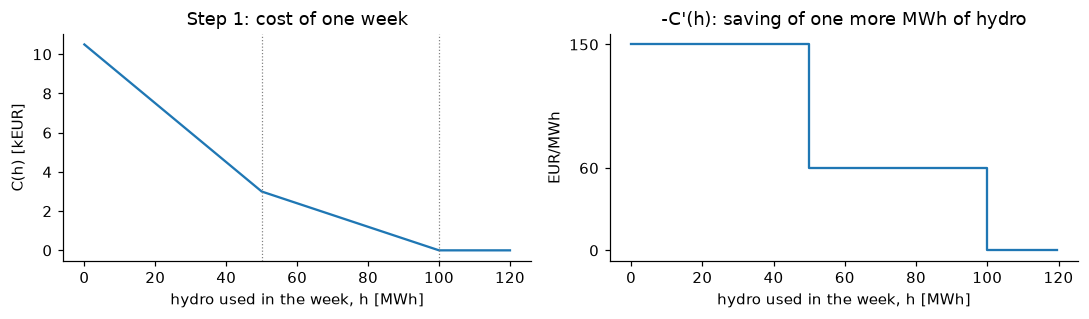

In [2]:
def week_cost(h):
    # C(h): cost of serving 100 MWh with h MWh of hydro, gas (50 MWh at 60) and peaker (150) for the rest
    rest = max(100.0 - h, 0.0)
    return 60.0 * min(rest, 50.0) + 150.0 * max(rest - 50.0, 0.0)

h = np.linspace(0, 120, 241)
C = np.array([week_cost(x) for x in h])
fig, ax = plt.subplots(1, 2, figsize=(10, 3.0))
ax[0].plot(h, C / 1e3)
for x in (50, 100):
    ax[0].axvline(x, color="grey", lw=0.8, ls=":")
ax[0].set(xlabel="hydro used in the week, h [MWh]", ylabel="C(h) [kEUR]", title="Step 1: cost of one week")
ax[1].step(h[:-1], -np.diff(C) / np.diff(h), where="post")
ax[1].set(xlabel="hydro used in the week, h [MWh]", ylabel="EUR/MWh", title="-C'(h): saving of one more MWh of hydro",
          yticks=[0, 60, 150])
plt.tight_layout()

### Step 2: the future cost function is an average over the two inflow scenarios

Week 1 leaves $v$ MWh. In week 2 nothing comes after, so it is optimal to use **all available water** (capped at the
100 MWh of demand, the rest is spilled):

* dry, probability $\tfrac12$: available water is $v$, so the cost is $C(v)$
* wet, probability $\tfrac12$: available water is $v + 60$, so the cost is $C(v+60)$

$$
\alpha(v) \;=\; \mathbb{E}\big[\text{cost of week 2}\big] \;=\; \tfrac12\, C(v) \;+\; \tfrac12\, C(v+60).
$$

### Step 3: write $\alpha(v)$ piece by piece

$C$ changes formula at $h = 50$ and $h = 100$. So:

* the **dry** term $C(v)$ changes formula where $v = 50$ and $v = 100$
* the **wet** term $C(v+60)$ changes formula where $v + 60 = 100$, i.e. $v = 40$
  ($v+60 = 50$ would need $v=-10$, which cannot happen)

Between the break points $v \in \{40,\,50,\,100\}$ both terms are linear, so $\alpha$ is linear too. Take
$0 \le v \le 40$ as the worked case:

* dry, $h = v \le 50$, first formula: $C(v) = 3000 + 150(50 - v) = 10\,500 - 150\,v$
* wet, $h = v+60 \in [60,\,100]$, second formula: $C(v+60) = 60\,(100 - v - 60) = 2400 - 60\,v$
* average: $\alpha(v) = \tfrac12(10\,500 - 150v) + \tfrac12(2400 - 60v) = 6450 - 105\,v$

Doing the same on every interval:

| $v$ (MWh) | dry: $C(v)$ | wet: $C(v+60)$ | $\alpha(v) = \tfrac12\,\text{dry} + \tfrac12\,\text{wet}$ |
|---|---|---|---|
| 0 – 40 | $10\,500 - 150v$ | $2400 - 60v$ | $6450 - 105\,v$ |
| 40 – 50 | $10\,500 - 150v$ | $0$ (wet week fully covered by hydro) | $5250 - 75\,v$ |
| 50 – 100 | $6000 - 60v$ | $0$ | $3000 - 30\,v$ |
| $\ge 100$ | $0$ | $0$ | $0$ |

The pieces join up: $\alpha(0) = 6450$, $\alpha(40) = 2250$, $\alpha(50) = 1500$, $\alpha(100) = 0$ EUR.

### Step 4: the water value is minus the slope

Differentiate $\alpha$ term by term:

$$
\lambda(v) \;=\; -\alpha'(v) \;=\; \tfrac12\,\big[-C'(v)\big] \;+\; \tfrac12\,\big[-C'(v+60)\big].
$$

Each bracket is "what one more MWh saves in that scenario" from step 1. So **the water value is the
probability-weighted saving of one extra MWh of stored water**:

| $v$ (MWh) | dry: extra MWh replaces | wet: extra MWh replaces | $\lambda(v)$ |
|---|---|---|---|
| 0 – 40 | peaker, 150 | gas, 60 | $\tfrac12 \cdot 150 + \tfrac12 \cdot 60 = $ **105** |
| 40 – 50 | peaker, 150 | nothing, 0 (would be spilled) | $\tfrac12 \cdot 150 + \tfrac12 \cdot 0 = $ **75** |
| 50 – 100 | gas, 60 | nothing, 0 | $\tfrac12 \cdot 60 + \tfrac12 \cdot 0 = $ **30** |
| $\ge 100$ | nothing | nothing | **0** |

These are exactly the slopes 105, 75, 30, 0 of the four lines in the step 3 table. The cell below draws the
figure. The dotted lines are the hand-derived formulas, the solid line is a brute-force computation of
$\tfrac12 C(v) + \tfrac12 C(v+60)$, and the cell checks that the two agree.

step 3 formulas match the brute-force alpha on every interval


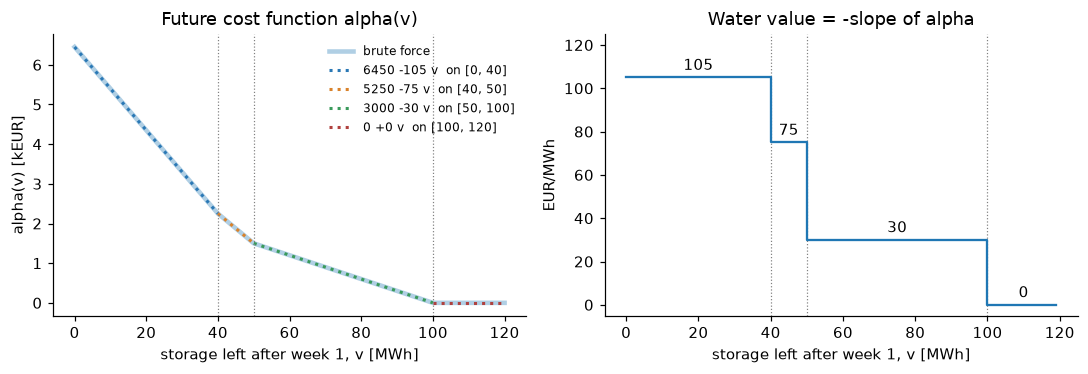

In [3]:
v = np.arange(0, 121)  # storage left after week 1, MWh
alpha = np.array([0.5 * week_cost(x) + 0.5 * week_cost(x + 60) for x in v])  # brute force, step 2
water_value = -np.diff(alpha)  # EUR/MWh, slope between v and v+1

# hand-derived pieces from step 3: (from, to, intercept, slope)
pieces = [(0, 40, 6450, -105), (40, 50, 5250, -75), (50, 100, 3000, -30), (100, 120, 0, 0)]
for lo, hi, a0, a1 in pieces:
    vv = v[(v >= lo) & (v <= hi)]
    assert np.allclose(a0 + a1 * vv, alpha[vv]), (lo, hi)  # step 3 formulas == brute force

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(v, alpha / 1e3, lw=3, alpha=0.35, label="brute force")
for (lo, hi, a0, a1), col in zip(pieces, plots.COLORS):
    vv = np.array([lo, hi])
    ax[0].plot(vv, (a0 + a1 * vv) / 1e3, ":", color=col, lw=2, label=f"{a0} {a1:+d} v  on [{lo}, {hi}]")
for b in (40, 50, 100):
    ax[0].axvline(b, color="grey", lw=0.8, ls=":")
    ax[1].axvline(b, color="grey", lw=0.8, ls=":")
ax[0].set(xlabel="storage left after week 1, v [MWh]", ylabel="alpha(v) [kEUR]", title="Future cost function alpha(v)")
ax[0].legend(frameon=False, fontsize=8)
ax[1].step(v[:-1], water_value, where="post")
for lo, hi, _, a1 in pieces:
    ax[1].annotate(f"{-a1}", ((lo + hi) / 2, -a1), textcoords="offset points", xytext=(0, 5), ha="center")
ax[1].set(xlabel="storage left after week 1, v [MWh]", ylabel="EUR/MWh", title="Water value = -slope of alpha",
          ylim=(-5, 125))
plt.tight_layout()
print("step 3 formulas match the brute-force alpha on every interval")

Two things in this example hold in general:

* **The water value falls as the reservoir fills.** Each $C$ is convex, and an average of convex functions is convex,
  so $\alpha$ is convex and its slope $-\lambda$ rises towards 0. More water in store means the next MWh replaces cheaper
  generation, or nothing at all because it would be spilled.
* **The water value is an expectation over the future**, not a cost of the plant. Here it mixes "replaces the peaker"
  (dry) with "replaces gas" or "is spilled" (wet). Nothing in the hydro plant's own costs appears in it.

## 1.2 The week-1 decision

Week 1 uses $u$ MWh of its 60 and keeps $v = 60 - u$, so

$$\text{total}(u) = C(u) + \alpha(60 - u).$$

Using one more MWh changes the total by $C'(u) - \alpha'(60-u) = -\big[-C'(u)\big] + \lambda(60-u)$. So:

$$\text{use one more MWh} \iff \underbrace{-C'(u)}_{\text{saving today}} \;>\; \underbrace{\lambda(60-u)}_{\text{saving later (water value)}}.$$

Walk $u$ upwards:

* **$u$ from 0 to 50.** Each MWh replaces the peaker today: saving 150. What is left, $v = 60-u$, falls from 60 to 10,
  where $\lambda$ is at most 105. Since $150 > 105$, keep using.
* **$u$ above 50.** Gas is now the marginal unit today: saving 60. What is left is below 10 MWh, where $\lambda = 105$.
  Since $60 < 105$, stop.

So **use 50 MWh, keep 10**. Expected total $= C(50) + \alpha(10) = 3000 + (6450 - 105\cdot 10) = 8400$ EUR.
Using all 60 now ("hydro bids like gas") gives $C(60) + \alpha(0) = 2400 + 6450 = 8850$ EUR.

**The price in week 1.** One more MWh of demand in week 1 can be met by the peaker (150) or by one more MWh of water,
which costs $\lambda(10) = 105$ in expected future cost. The cheaper option sets the price: **105 EUR/MWh**. At the optimum the
marginal value today equals the water value, which is eq. (4.6) in the SINTEF report,
$\partial\phi_t/\partial e_t = \partial\alpha_{t+1}/\partial v_t$.

use 50 MWh now, keep 10 MWh. Expected total cost 8,400 EUR
naive (hydro bids like gas, uses all 60 now): 8,850 EUR


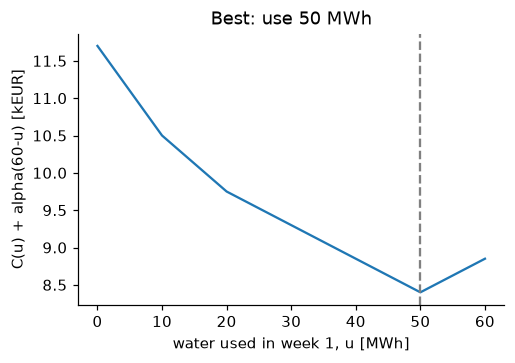

In [4]:
use = np.arange(0, 61)
total = np.array([week_cost(u) + alpha[60 - u] for u in use])
best = use[np.argmin(total)]
fig, ax = plt.subplots(figsize=(5, 3.2))
ax.plot(use, total / 1e3); ax.axvline(best, color="grey", ls="--")
ax.set(xlabel="water used in week 1, u [MWh]", ylabel="C(u) + alpha(60-u) [kEUR]", title=f"Best: use {best} MWh")
print(f"use {best} MWh now, keep {60 - best} MWh. Expected total cost {total.min():,.0f} EUR")
print(f"naive (hydro bids like gas, uses all 60 now): {total[-1]:,.0f} EUR")

## 1.3 The same thing as one LP: price and water value come out together

This is Arild's point: you do **not** need a price forecast. Write both weeks and both inflow scenarios as one
linear program (the "extensive form"). The dual of the **reservoir balance** is the water value, and the dual of the
**power balance** is the electricity price. Both are outputs of the same optimisation.

In [5]:
h = highspy.Highs(); h.silent()
hyd1, gas1, peak1, keep = (h.addVariable(lb=0, ub=ub) for ub in (60, 50, 1e9, 60))
h.addConstr(hyd1 + keep == 60)                                   # reservoir week 1
pb1 = h.addConstr(hyd1 + gas1 + peak1 == 100)                    # power balance week 1
obj = 60 * gas1 + 150 * peak1
pb2 = []
for inflow in (0, 60):                                           # week 2, one copy per scenario
    hyd2, gas2, peak2 = h.addVariable(lb=0), h.addVariable(lb=0, ub=50), h.addVariable(lb=0)
    h.addConstr(hyd2 <= keep + inflow)                           # reservoir week 2
    pb2.append(h.addConstr(hyd2 + gas2 + peak2 == 100))
    obj = obj + 0.5 * (60 * gas2 + 150 * peak2)
h.minimize(obj)
dual = np.array(h.getSolution().row_dual)
print(f"hydro used week 1      : {h.val(hyd1):.0f} MWh")
print(f"price week 1           : {dual[pb1.index]:.0f} EUR/MWh   <- equals the water value")
print(f"price week 2 dry / wet : {dual[pb2[0].index] / 0.5:.0f} / {dual[pb2[1].index] / 0.5:.0f} EUR/MWh "
      f"(expected {dual[pb2[0].index] + dual[pb2[1].index]:.0f})")

hydro used week 1      : 50 MWh
price week 1           : 105 EUR/MWh   <- equals the water value
price week 2 dry / wet : 150 / 60 EUR/MWh (expected 105)


**The price in week 1 is 105 EUR/MWh.** That is neither gas (60) nor the peaker (150) but the water value: the
hydro plant is the marginal unit, and its "marginal cost" is the opportunity cost of water.

## 1.4 The general recursion

For weeks $t = 1..T$ with storage $v$ and uncertain inflow, dynamic programming gives

$$
Q_t(v_{t-1}, \xi_t) = \min_{\text{dispatch of week } t}\; \underbrace{c_t(\cdot)}_{\text{market cost of week } t}
\;+\; \alpha_t(v_t),
\qquad
\alpha_t(v_t) = \mathbb{E}_{\xi_{t+1}}\big[Q_{t+1}(v_t, \xi_{t+1})\big]
$$

and the water value in week $t$ is $\lambda_t(v) = -\partial\alpha_t/\partial v$. Solving this backwards from the
last week gives every $\alpha_t$. The hard part is representing $\alpha_t$ when $v$ has many dimensions.

---
# Part 2: from dynamic programming to SDDP

Classic stochastic dynamic programming (SDP) tabulates $\alpha_t(v)$ on a grid. With 20 levels per reservoir,
3 reservoirs need $20^3 = 8\,000$ grid points per week, and 30 reservoirs need $10^{39}$. This is the **curse of
dimensionality**, and it is why EMPS-type models aggregate hydro into one reservoir per area.

SDDP avoids the grid. Because every week is an LP, $\alpha_t$ is **convex and piecewise linear** in $v$,
so it can be approximated **from below** by tangent planes (cuts):

$$\alpha_t(v, z) \;\ge\; \beta_c + \pi^v_c \cdot v + \pi^z_c \cdot z \qquad \forall c$$

Each iteration of SDDP has two passes:

* **Forward pass:** simulate a few inflow scenarios through all weeks with the current cuts. This finds the
  states the system actually visits.
* **Backward pass:** at those states, from the last week back to the first, solve week $t$ for every inflow branch.
  The average objective and its **duals with respect to the incoming storage** give a new cut for $\alpha_{t-1}$.

The cut slope $\pi^v$ is exactly the (negative) water value. Below, a one-area version (OTRA alone, no grid,
104 weeks so that week 30 is far from the end of the horizon) shows the cuts accumulating for one week.

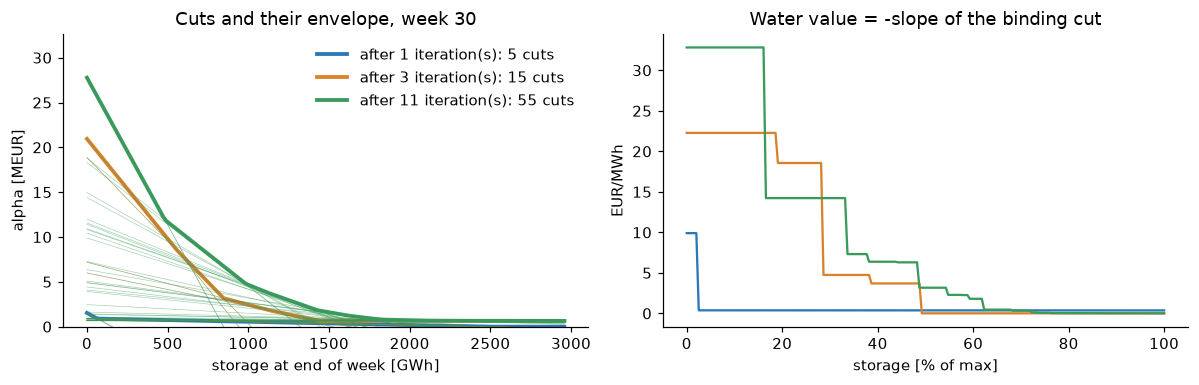

In [6]:
one = load_case(areas=["OTRA"])
st1, _ = train(one, n_stages=104, n_scen=5, max_iter=12, verbose=False)
week = 30
beta, ccr, cci = st1.cut_arrays(week - 1)
vgrid = np.linspace(0, one.max_res[0], 200)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
done = len(beta) // 5                                                # iterations with a backward pass
for k, col in zip((1, 3, done), plots.COLORS):
    n = k * 5
    vals = beta[:n, None] + ccr[:n, 0, None] * vgrid[None, :]       # z = 0 (average inflow)
    for c in range(n):
        ax[0].plot(vgrid, vals[c] / 1e3, color=col, lw=0.4, alpha=0.5)
    env = np.maximum(vals.max(axis=0), 0)
    ax[0].plot(vgrid, env / 1e3, color=col, lw=2.5, label=f"after {k} iteration(s): {n} cuts")
    wv = -ccr[:n, 0][np.argmax(vals, axis=0)]
    ax[1].plot(100 * vgrid / one.max_res[0], wv, color=col, label=f"after {k} iteration(s)")
ax[0].set(ylim=(0, None), xlabel="storage at end of week [GWh]", ylabel="alpha [MEUR]",
          title=f"Cuts and their envelope, week {week}")
ax[1].set(xlabel="storage [% of max]", ylabel="EUR/MWh", title="Water value = -slope of the binding cut")
ax[0].legend(frameon=False); plt.tight_layout()

Thin lines are individual cuts and thick lines are their envelope (the approximate FCF). More iterations add cuts
where the system goes, and the envelope tightens. Two practical consequences:

* **Water values are only reliable where cuts were built.** At storage levels the forward pass never visits
  (here, very full or very empty), the envelope is an extrapolated straight line.
* **The water value is a step function of storage**, one step per binding cut, just like the step curve in 1.1.

---
# Part 3: the 4-area toy, inputs

The toy reads 13 CSV files from `data/toy_4area/`. They are exported from the EMPS files with ReSDDP's own
readers, so the numbers are what ReSDDP optimises over (after aggregation and after `LoadScale = 1.2`,
`LineCapScale = 0.8` from the dataset's `params.jl`).

| toy CSV | content | EMPS / ReSDDP source |
|---|---|---|
| `areas.csv`, `lines.csv` | 4 price areas, 8 directed lines (GWh/week, loss) | `model.h5`, `MASKENETT.DATA` |
| `hydro.csv`, `hydro_min_prod.csv` | 3 aggregated hydro systems: max storage, max/min production | `model.h5`, `DYNMODELL.OM*`, aggregated by `aggregate.jl` |
| `inflow_history.csv` | weekly energy inflow, 50 historical years | `historical.h5` |
| `inflow_stats.csv`, `inflow_phi.csv`, `inflow_residuals.csv` | AR(1) inflow model: mean, sdev, $\Phi$, 5 noise branches | `InflowModelLOG.dat` (fitted by SINTEF's `infmod.R`) |
| `supply_steps.csv` | supply curve per area: capacity (GWh/week) and price | `TidsserieData.h5` (TRINN) |
| `load.csv`, `wind.csv` | firm load and wind per area and block | `TidsserieData.h5` (DELLASTER), `wind_data.h5` |
| `parameters.csv` | blocks per week (7 = daily), rationing and spill cost | `params.jl` |

In [7]:
case = load_case()
print(f"{case.A} areas, {case.S} hydro systems, {case.J} supply steps, {case.L} directed lines, "
      f"{case.K} blocks/week, {case.B} inflow branches, {case.Y} historical years")
pd.read_csv("data/toy_4area/hydro.csv")

4 areas, 3 hydro systems, 27 supply steps, 8 directed lines, 7 blocks/week, 5 inflow branches, 50 historical years


,system,area,area_name,max_res_GWh,max_prod_GWh_per_week,res_init_GWh
0,1,1,NUMEDAL,1546.9,102.5,773.5
1,2,2,TEV,1672.8,89.9,836.4
2,3,3,OTRA,2958.1,137.7,1479.1


In [8]:
pd.read_csv("data/toy_4area/lines.csv")

,line,from_area,from_name,to_area,to_name,cap_GWh_per_week,loss
0,1,1,NUMEDAL,2,TEV,9.4,2.0e-02
1,2,2,TEV,1,NUMEDAL,9.4,2.0e-02
2,3,2,TEV,3,OTRA,9.4,2.0e-02
3,4,3,OTRA,2,TEV,9.4,2.0e-02
4,5,3,OTRA,1,NUMEDAL,9.4,2.0e-02
5,6,1,NUMEDAL,3,OTRA,9.4,2.0e-02
6,7,3,OTRA,4,TERM,134.4,4.0e-02
7,8,4,TERM,3,OTRA,134.4,4.0e-02


The grid is a triangle of three hydro areas (NUMEDAL, TEV, OTRA) linked by small 70 MW lines, with a thermal area
(TERM) connected to OTRA by 1000 MW.

**Supply curve.** Every area has a huge step at ~0 EUR/MWh with **negative** capacity: a sink that can absorb surplus
energy for free. All other steps are supply: thermal units, plus "Rasjonering"/"Flomkraft" steps priced like
expensive emergency supply. Load the market cannot meet is rationed at 400 EUR/MWh.

In [9]:
steps = pd.read_csv("data/toy_4area/supply_steps.csv")
steps.pivot_table(index=["area_name", "step_name"], values=["capacity_GWh_per_week", "price_EUR_per_MWh"],
                  sort=False)

capacity_GWh_per_week  price_EUR_per_MWh
area_name step_name                                                  
NUMEDAL   VARMEKRAFT 1                     -1680.0            1.0e-02
          VARMEKRAFT 2                         8.4            4.0e+00
          VARMEKRAFT 3                         1.7            8.0e+00
          VARMEKRAFT 4                         1.7            1.4e+01
          VARMEKRAFT 5                         1.7            1.7e+01
          VARMEKRAFT 6                         1.7            2.2e+01
          VARMEKRAFT 7                         1.7            4.5e+01
          Rasjonering                          8.4            6.0e+01
          Flomkraft                           16.8            1.0e+02
TEV       KJELKRAFT 25 \RE                 -1680.0            1.0e-02
          KRAFT UTEN MARKED                    8.4            6.0e+00
          Rasjonering                          8.4            3.5e+01
OTRA      VARMEKRAFT - 1                   -1680.0            1.0e-02
          VARMEKRAFT - 2                       5.0            1.3e+01
          VARMEKRAFT - 3                       1.7            1.7e+01
          VARMEKRAFT - 4                       8.4            2.6e+01
          VARMEKRAFT - 5                       3.4            3.2e+01
          VARMEKRAFT - 6                       3.4            3.8e+01
          Rasjonering                          8.4            4.8e+01
          Flomkraft                           16.8            8.0e+01
TERM      KJELKRAFT 25 \RE                 -1680.0            1.0e-02
          startk_enhet                         3.4            1.0e+01
          Grunnlast                            3.4            1.5e+01
          Gass1                                3.4            2.0e+01
          Gass2                                3.4            2.5e+01
          KRAFT UTEN MARKED                    8.4            3.0e+01
          Rasjonering                         16.8            5.0e+01

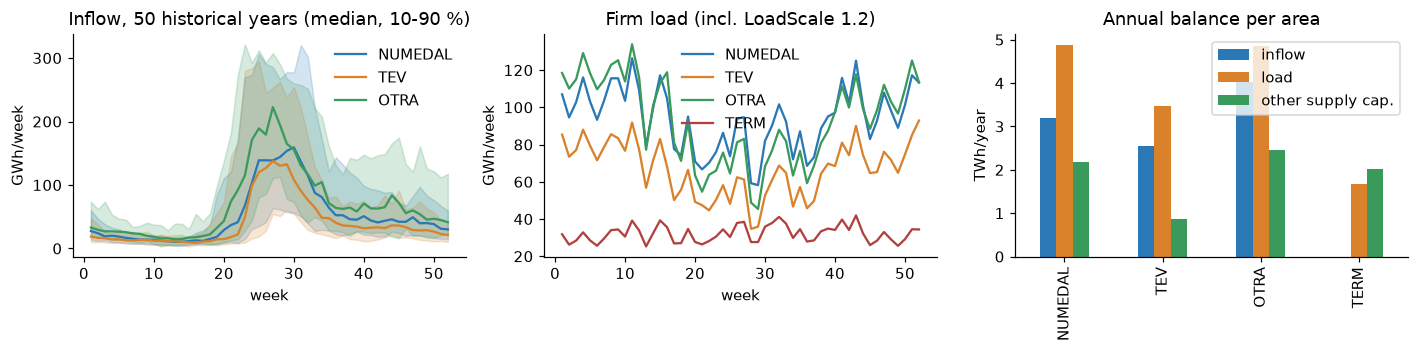

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.3))
weeks = np.arange(1, 53)
for s, name in enumerate(case.system_names()):
    plots.fan(ax[0], case.infl_hist[s].T, plots.COLORS[s], name)
ax[0].set(xlabel="week", ylabel="GWh/week", title="Inflow, 50 historical years (median, 10-90 %)")
ax[0].legend(frameon=False)
for a, name in enumerate(case.area_names):
    ax[1].plot(weeks, case.load[a].sum(axis=1), color=plots.COLORS[a], label=name)
ax[1].set(xlabel="week", ylabel="GWh/week", title="Firm load (incl. LoadScale 1.2)"); ax[1].legend(frameon=False)
annual = pd.DataFrame({
    "inflow": [case.infl_hist[case.sys_area == a].sum(axis=1).mean() if (case.sys_area == a).any() else 0
               for a in range(case.A)],
    "load": case.load.sum(axis=(1, 2)),
    "other supply cap.": [52 * case.step_cap[(case.step_area == a) & (case.step_cap > 0)].sum() for a in range(case.A)],
}, index=case.area_names) / 1e3
annual.plot.bar(ax=ax[2], color=plots.COLORS[:3]); ax[2].set(ylabel="TWh/year", title="Annual balance per area")
plt.tight_layout()

The system is **short of water**: 9.8 TWh of average inflow against 14.9 TWh of load. Thermal and emergency supply have
to fill the gap, and they are limited by the weak grid. Inflow arrives mostly with the snowmelt (weeks 20-32),
while load is highest in winter. **Storing water from summer to winter is the whole game**, and the water value is its price.

**Inflow model.** ReSDDP does not sample historical years directly. It uses a statistical model fitted to them:

$$I_{s,t} = \mu_{s,w} + \sigma_{s,w}\, z_{s,t}, \qquad z_t = \Phi\, z_{t-1} + \varepsilon_t,$$

with $\varepsilon_t$ drawn from 5 equally likely residual vectors per week. $\Phi$ (diagonal ~0.65) makes inflow
persistent (a wet week tends to follow a wet week), so last week's $z$ becomes a **second state variable** next to
storage, and the cuts get a coefficient on it (`CCI` in ReSDDP).

In [11]:
pd.DataFrame(case.phi, index=case.system_names(), columns=case.system_names())

,NUMEDAL,TEV,OTRA
NUMEDAL,6.9e-01,1.2e-01,5.7e-02
TEV,1.6e-02,6.7e-01,4.9e-02
OTRA,1.1e-02,2.9e-02,6.2e-01


---
# Part 4: the equations

One **stage** is one week $w$ split into $K = 7$ blocks $k$ (days), $\tau = 1/K$. This is ReSDDP's
`StageProbFull.Build` (`src/stageprob_full.jl`), eq. (2.7)/(3.11) in the report, written in
`resddp_toy/model.py::add_week`. The row names match the Julia code.

**Objective (kEUR):**

$$\min \sum_k\Big[\sum_j c_j x_{jk} + c^{rat}\sum_a r_{ak} + c^{spill}\sum_s q_{sk} + c^{neg}\sum_s n_{sk}\Big] + \alpha$$

| row | equation | meaning / dual |
|---|---|---|
| `rstate` | $v^0_s = \hat v_s$ | copy of incoming storage. **Dual $\pi^v_s$, water value $= -\pi^v_s$** |
| `zstate` | $z^0_s = \hat z_s$ | copy of incoming inflow state. Dual $\pi^z_s$ |
| `inflow` | $I_s - \sigma_{sw}\sum_j \Phi_{sj} z^0_j = \mu_{sw} + \sigma_{sw}\varepsilon_s$ | inflow this week (GWh) |
| `zend` | $z_s - \sum_j \Phi_{sj} z^0_j = \varepsilon_s$ | outgoing inflow state |
| `resbal` | $v_{sk} - v_{s,k-1} + p_{sk} + q_{sk} - n_{sk} - \tau I_s = 0$ | reservoir balance per block ($v_{s0}=v^0_s$) |
| `pbal` | $\sum_{s\in a} p_{sk} + \sum_{j\in a} x_{jk} + u_{ak} + r_{ak} - \sum_{\ell\,\text{out}} f_{\ell k} + \sum_{\ell\,\text{in}} (1-\text{loss}_\ell) f_{\ell k} = D_{awk}$ | power balance. **Dual = price** |
| `cut` | $\alpha - \sum_s \text{CCR}_{cs} v_{sK} - \sum_s \text{CCI}_{cs} z_s \ge \beta_c$ | future cost function |

**Bounds:** $0\le v\le \bar V_s$; $\tau \underline P_{sw}\le p\le \tau \bar P_s$; $\tau\min(0,C_j)\le x_j\le\tau\max(0,C_j)$;
$0\le f\le \tau F_\ell$; $0\le u\le W_{awk}$; $q,n,r\ge 0$; $\alpha\ge 0$.

**Cut from the backward pass** (`resddp_toy/sddp.py::_backward_stage`, ReSDDP `SolveBWD`): at trial state
$(\hat v,\hat z)$ solve week $t$ for each branch $b$ (probability $1/B$), then

$$\text{CCR} = \tfrac1B\sum_b \pi^v_b,\quad \text{CCI} = \tfrac1B\sum_b \pi^z_b,\quad
\beta = \tfrac1B\sum_b Q_b - \text{CCR}\cdot\hat v - \text{CCI}\cdot\hat z,$$

which is added to week $t-1$ as $\alpha_{t-1} \ge \beta + \text{CCR}\cdot v + \text{CCI}\cdot z$.

**What the toy leaves out** (all present in ReSDDP): feasibility cuts for detailed hydro (`LFeasCut`),
cost cuts / residual demand cost function (`LCostApprox`), ramping and reserve capacity, H2 storage, demand response,
stochastic wind (`LWindStoch`), and parallel scenario clusters.

---
# Part 5: results

## 5.1 Training

`tools/train_4area.py` trains a **156-week (3-year)** strategy with 20 forward scenarios. The first years are used
for decisions, and the last year absorbs the end-of-horizon effect (the dataset values water left after the last week
at zero, `EndValueCuts.dat = NONE`). Training takes several minutes, so the notebook loads the saved result.

45 iterations, 880 cuts per stage, final lower bound 138.4 MEUR


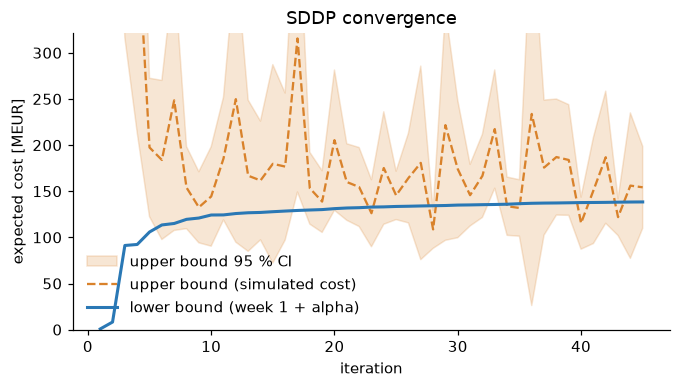

In [12]:
strategy_file = ROOT / "results" / "strategy_4area.npz"
if strategy_file.exists():
    st = Strategy.load(strategy_file)
else:  # quick fallback so the notebook always runs
    st, _ = train(case, n_stages=156, n_scen=10, max_iter=15)
print(f"{len(st.lower)} iterations, {st.n_cuts(60)} cuts per stage, final lower bound {st.lower[-1]/1e3:.1f} MEUR")
plots.convergence(st);

The **lower bound** (cost of week 1 plus $\alpha_1$) can only rise as cuts are added. The **upper bound** is the
average simulated cost over the forward scenarios. It is a noisy sample mean, so it jumps around, and with few
scenarios it can even dip below the lower bound. In practice you stop when the lower bound has flattened and lies
inside the upper bound's confidence band. That is also how the SINTEF report judges convergence (section 5.3).
Here the lower bound is still creeping up (well under 1 % per 5 iterations at the end), so the strategy is good
enough for learning but not fully converged. More iterations and scenarios would tighten it.

## 5.2 Water values

Read the cuts at fixed storage levels with average inflow ($z = 0$), as in section 6.5 of the report. Week numbers
refer to the **second year** of the horizon, where forward scenarios have spread out and the end of the horizon is
still a year away.

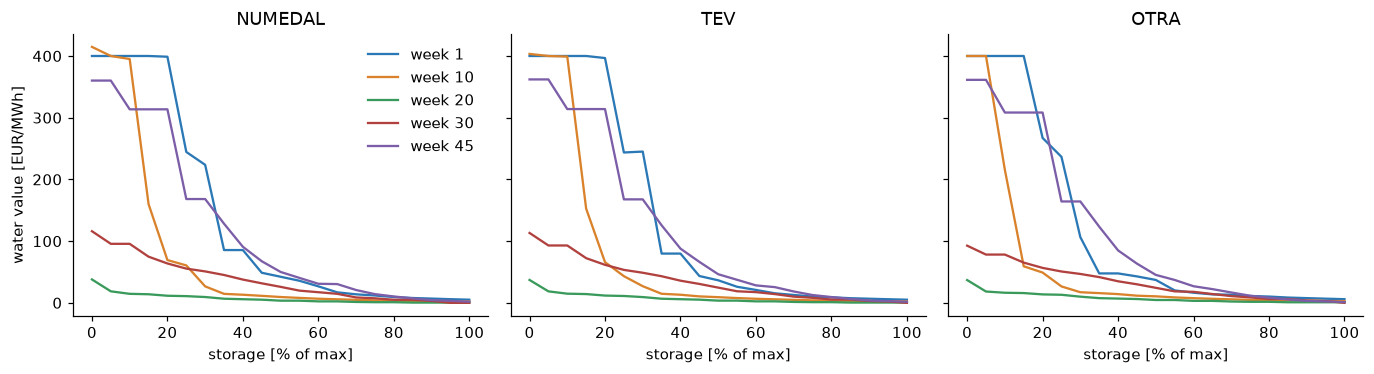

In [13]:
fillings = np.linspace(0, 1, 21)
wv = water_value_matrix(case, st, year=1, fillings=fillings)      # [week, filling, system]
plots.water_value_curves(case, wv, fillings, weeks=(1, 10, 20, 30, 45));

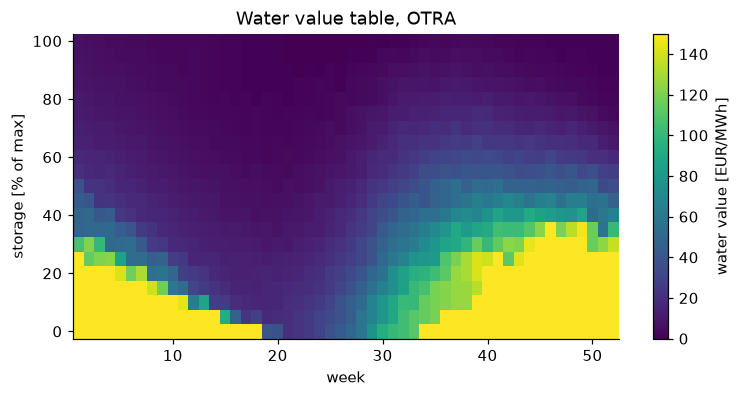

In [14]:
fig = plots.water_value_heatmap(case, wv, fillings, system=2, vmax=150)

Things to notice:

* **Water values fall as the reservoir fills.** An empty reservoir risks rationing (400 EUR/MWh) and a full one risks
  spilling (about 0).
* **They depend on the season.** Before the snowmelt (weeks 10-17) water is very valuable at low storage, because the
  winter has to be survived on what is left. Right after the melt it is cheap.
* This **week × storage table** is the classic "water value matrix". It is what you could hand to a market model
  as the bid price of hydro.

In [15]:
table = to_frame(case, wv, fillings)
table.to_csv(ROOT / "results" / "water_values_4area.csv", index=False)
table.head()

,week,filling,system,water_value_EUR_per_MWh
0,1,0.0e+00,NUMEDAL,400.0
1,1,0.0e+00,TEV,400.0
2,1,0.0e+00,OTRA,400.0
3,1,5.0e-02,NUMEDAL,400.0
4,1,5.0e-02,TEV,400.0


## 5.3 Simulating with the strategy

Now run the strategy on the **50 historical inflow years** (out of sample: training used the statistical model).
Each week the market LP is solved with the cuts. Prices, reservoir levels and water values are all outputs.

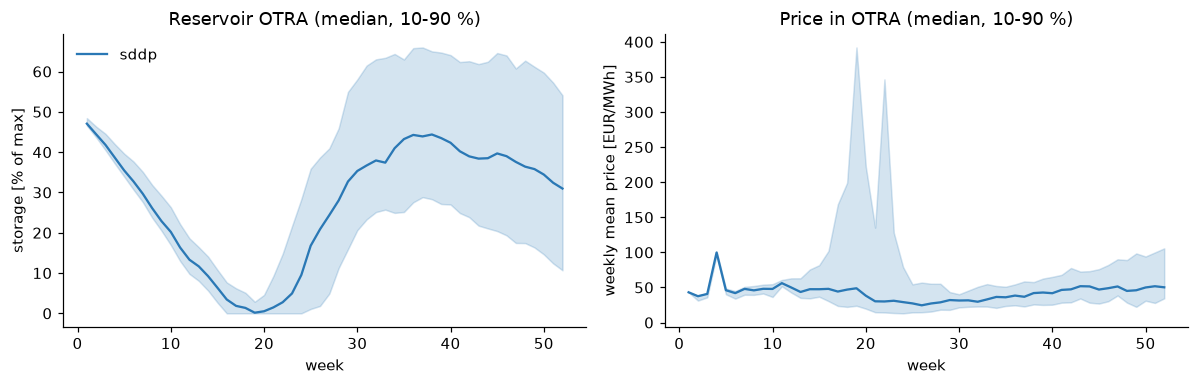

In [16]:
stages = stages_from_strategy(case, st)
sim = simulate(case, st, "sddp", stages=stages)
fig = plots.storage_and_price(case, [sim], system=2)

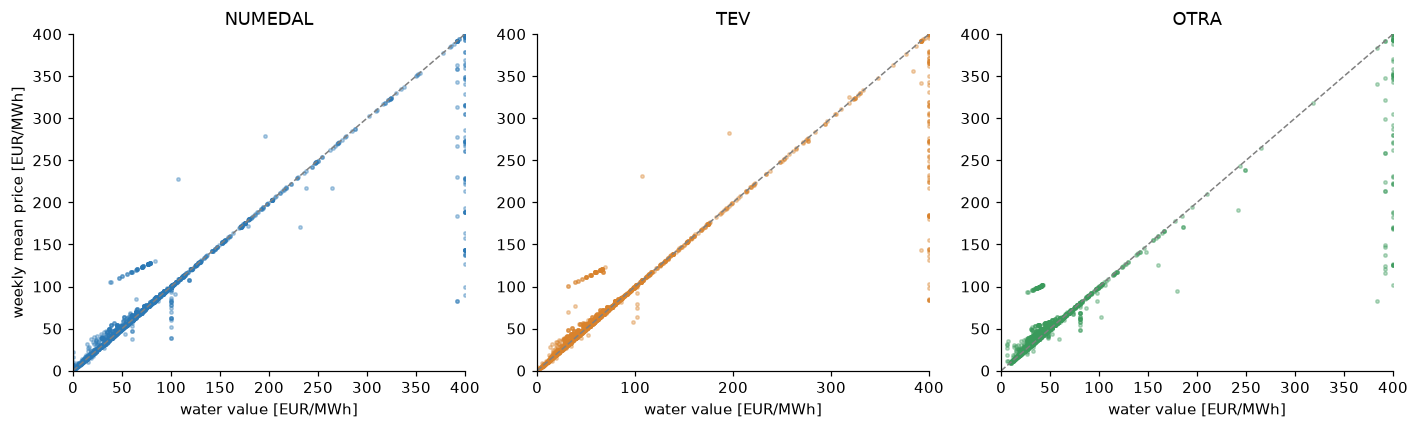

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for s in range(case.S):
    a = case.sys_area[s]
    wv_s = sim.water_value[:, :, s].ravel(); pr = sim.price[:, :, a, :].mean(axis=2).ravel()
    axes[s].scatter(wv_s, pr, s=5, alpha=0.35, color=plots.COLORS[s])
    m = np.quantile(np.r_[wv_s, pr], 0.99); axes[s].plot([0, m], [0, m], "--", color="grey", lw=1)
    axes[s].set(xlim=(0, m), ylim=(0, m), xlabel="water value [EUR/MWh]", title=case.area_names[a])
axes[0].set_ylabel("weekly mean price [EUR/MWh]"); plt.tight_layout()

Each dot is one week of one historical year. Most weeks sit on the diagonal: **the area price equals the water value of
its reservoir**. That is eq. (4.6) at work, with hydro as the price-setting unit. Points away from the line are weeks where
hydro hits a limit: it runs at full capacity (price above the water value), it is held at minimum production or the
reservoir is spilling (price below), or the weak 70 MW lines separate the areas.

---
# Part 6: coupling water values with a market model

There are three ways to bring water values into a dispatch model like enlight. Each is run below on the same weekly
market LP and the same 50 historical years:

| policy | what the weekly market LP contains | analogue |
|---|---|---|
| `sddp` | the **cuts**: objective includes $\alpha_t(v_{end}, z_{end})$, so storage, water value and price are solved **together** | ReSDDP `simulate_aggregated`. In enlight: add a reservoir state, $\alpha$ and the week's cuts |
| `wv_table` | no cuts; water left at the end of the week is worth a **fixed** water value from the week × storage table | "water value as input" (today's enlight approach, with SDDP numbers) |
| `fixed_cost` | no cuts; hydro bids a **fixed cost** (20 EUR/MWh, gas-like) and stored water has no value | enlight's current assumption |
| `perfect_foresight` | the whole year as **one LP** with all 52 weeks of inflow known | benchmark only. No operator knows the future |

All runs start at 50 % storage. The water left after week 52 is charged with the same SDDP future cost function, so a
policy cannot look cheap by emptying the reservoirs at the end of the year.

In [18]:
results = [
    sim,
    simulate(case, st, "wv_table", wv_matrix=wv, wv_fillings=fillings),
    simulate(case, st, "fixed_cost", hydro_cost=20.0),
    perfect_foresight(case, st),
]
summary = summary_table(case, results)
summary.T

policy,sddp,wv_table,fixed_cost,perfect_foresight
expected cost incl. end state [MEUR],281.2,315.5,577.0,236.1
operating cost year 1 [MEUR],146.2,176.1,246.2,132.0
future cost of end state [MEUR],135.0,139.3,330.8,104.0
mean price [EUR/MWh],65.3,69.3,67.4,57.6
price std [EUR/MWh],70.5,82.2,115.7,35.6
rationing [GWh/yr],54.1,118.9,421.8,2.2
spill [GWh/yr],11.9,46.1,39.4,2.4
lowest storage [% of max],0.0,0.0,0.0,0.0
end storage [% of max],40.9,42.3,25.3,46.0


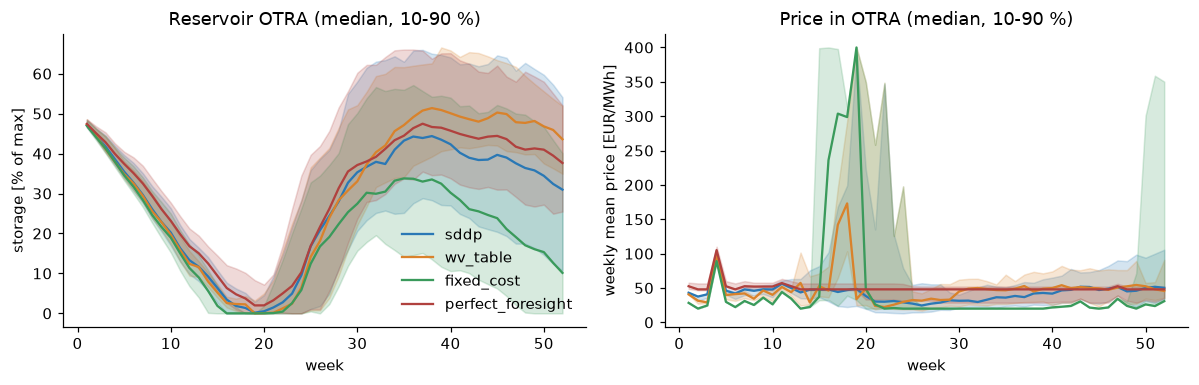

In [19]:
fig = plots.storage_and_price(case, results, system=2)

### Reading the comparison

* **`fixed_cost`** (hydro priced like gas, about twice the cost of `sddp`). Water is used whenever the price exceeds
  20 EUR/MWh, with no regard for later weeks. The reservoirs are empty earlier and longer before the snowmelt
  (weeks 14-20), prices hit the 400 EUR/MWh rationing level there, rationing is about 8 times higher, and the year
  ends with far less water (25 % against 41 %). This is why a fixed marginal cost for reservoir hydro gives wrong prices.
* **`wv_table`** (water value as input) is much better than `fixed_cost` but clearly worse than `sddp`: about 12 %
  higher cost and twice the rationing, with a price spike before the snowmelt in some years. The differences are
  structural. One number per week is fixed at the start of the week, so it cannot react to what happens during the week.
  The table assumes all reservoirs are equally full and inflow is average ($z = 0$). And the value is linear, so the LP
  sees no difference between keeping 1 GWh or 500 GWh.
* **`sddp`** (cuts inside the market LP). The FCF is a *function* of the end-of-week state of all reservoirs and the
  inflow state, so the market LP itself trades water now against water later, block by block and across areas.
* **`perfect_foresight`** is cheaper than anything achievable (about 16 % below `sddp`), because it "knows" whether
  the year will be wet or dry. Its gap to `sddp` is the value of perfect information, not a flaw of SDDP. Its prices
  are also much smoother (std 36 against 71 EUR/MWh). A deterministic year-long LP over a historical inflow year in
  enlight would give these over-optimistic, too-smooth prices.

### So, can you solve them together?

**Yes, and that is what the `sddp` policy does.** The SDDP strategy (the cuts) is computed once, offline, by a model
of the same power system. Then each weekly market solve includes the reservoir balance, $\alpha$ and that week's cuts.
The water value and the price come out of the same LP as duals, so there is no loop and no price forecast.
What you cannot do in a single deterministic LP is handle the *uncertainty* of future inflow, and that is the part SDDP
pre-computes into the cuts.

---
# Part 7: where this sits in ReSDDP and enlight

See `README.md` for the file-by-file mapping between ReSDDP (Julia) and this toy, what a full Python port would
need, and a sketch of the enlight change (`docs/enlight_integration.md`).